# Task 1: Explore Weather Patterns
## Singapore Rainfall, 2017–2024

This notebook explores rainfall patterns across Singapore from 2017 to 2024, examining how rainfall varies within a year and how these patterns differ across years and monitoring stations.

The analysis investigates:

- **Seasonal patterns:** Which months typically experience more or less rainfall?
- **Annual differences:** How do rainfall amounts and monthly patterns vary across years?
- **Time-of-day patterns:** When does rainfall occur, and does this change with the season?
- **Rainfall frequency and intensity:** Are wetter periods associated with more frequent rain, larger rainfall amounts, or both?
- **Spatial variation:** How do rainfall patterns differ between stations?

Building on the preceding data preparation, observation coverage is assessed and rainfall is aggregated at station level before comparisons are made. Visualisations and summary statistics are used to present the findings and discuss their limitations.

The findings also inform **Task 2: Predict Rainfall** by motivating candidate predictors such as station identity, month, hour and recent rainfall history for estimating the probability of exceeding a specified rainfall amount in the next 30 minutes.

## 1.1 Spark Session

In [20]:
import socket
from pyspark.sql import SparkSession

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspark.sql.functions as F
import seaborn as sns
import pandas as pd

import os
import sys

In [21]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-ashley-1-m
Spark master:  yarn
Spark version: 3.5.3


## 1.2 Reading the Cleaned Rainfall Data

In [22]:
rain = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/parquet/")

## 1.3 Seasonal Patterns: Which Months Are Wetter or Drier?

This section examines the typical monthly rainfall pattern across 2017–2024. Estimated rainfall is first calculated for each year–month, then averaged across years to produce a January–December profile.

The resulting chart shows which calendar months tend to be wetter or drier during the study period. These estimates are based on available observations and may be affected by missing records and changes in the reporting stations.

In [23]:
# Step 1: Extract the year and month from the observation date
rain = (
    rain.withColumn("date", F.to_date("date"))
        .withColumn("year", F.year("date"))
        .withColumn("month", F.month("date"))
)

# Step 2: Calculate mean rainfall per observed five-minute interval
# for each year and month
monthly_spk = (
    rain.filter(F.col("year").between(2017, 2024))
        .groupBy("year", "month")
        .agg(
            F.avg("reading_value").alias("mean_per_interval"),
            F.countDistinct("station_id").alias("n_stations")
        )
        .withColumn(
            "year_month",
            F.make_date("year", "month", F.lit(1))
        )
        .withColumn(
            "days",
            F.dayofmonth(F.last_day("year_month"))
        )
        # mean interval rainfall × expected intervals in the month
        # There are 12 five-minute intervals per hour and 24 hours per day
        .withColumn(
            "avg_rainfall_monthly",
            F.col("mean_per_interval") * F.col("days") * 24 * 12
        )
        .orderBy("year_month")
)

+-----+---------------------+-------+
|month|mean_monthly_rainfall|n_years|
+-----+---------------------+-------+
|1    |242.7139914632278    |8      |
|2    |138.03910167348224   |8      |
|3    |204.13985689807674   |8      |
|4    |247.79857154399454   |8      |
|5    |217.79066209049313   |8      |
|6    |234.69007672407554   |8      |
|7    |148.52206350834817   |8      |
|8    |162.4947365901557    |8      |
|9    |207.5473359865518    |8      |
|10   |208.78946914641156   |8      |
|11   |312.5108928978004    |8      |
|12   |262.27824664072386   |8      |
+-----+---------------------+-------+



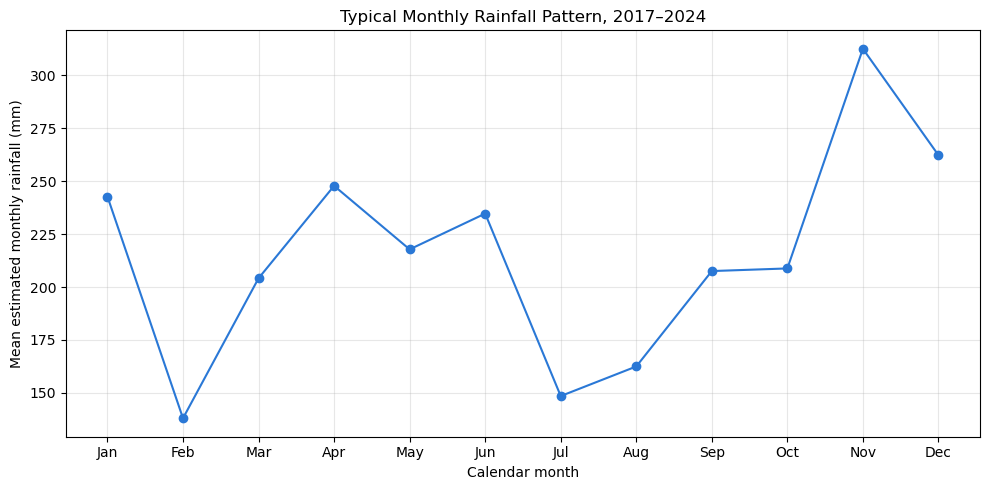

In [24]:
# Step 3: Average each calendar month's estimate across years
# For example, average January 2017, January 2018, ..., January 2024
seasonal_spk = (
    monthly_spk.groupBy("month")
        .agg(
            F.avg("avg_rainfall_monthly").alias("mean_monthly_rainfall"),
            F.countDistinct("year").alias("n_years")
        )
        .orderBy("month")
)

seasonal_spk.show(12, truncate=False)

# Step 4: Convert the small monthly summary to pandas
seasonal_df = seasonal_spk.toPandas()

# Step 5: Plot the January–December rainfall profile
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonal_df["month"],
    seasonal_df["mean_monthly_rainfall"],
    marker="o",
    color="#2a78d6"
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_xlabel("Calendar month")
ax.set_ylabel("Mean estimated monthly rainfall (mm)")
ax.set_title("Typical Monthly Rainfall Pattern, 2017–2024")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **November has the highest mean estimated rainfall**, at approximately **310 mm**, followed by December at around **260 mm**.
- **February is the driest month on average**, at approximately **140 mm**. July and August also have relatively low rainfall.
- Rainfall rises from February to April, fluctuates through June, and drops sharply in July. It then generally increases towards the November peak.
- The pattern suggests **seasonal variation**, with wetter conditions towards the end of the year and relatively drier conditions in February and July–August.
- These values are averages across **2017–2024**. They do not mean that November was the wettest month in every year. The next section examines how rainfall differs between individual years.

## 1.4 Annual Differences: How Does Rainfall Vary Across 2017–2024?

The previous section summarised the typical monthly rainfall pattern across eight years. This section compares individual years to identify wetter and drier periods.

Estimated annual rainfall is calculated from the mean recorded five-minute rainfall amount, scaled to the number of intervals in each year. A bar chart compares these estimates, with the number of reporting stations shown for context.

The estimates may be affected by missing observations and differences in station coverage.

+----+--------------------+----------+----+------------------+
|year|mean_per_interval   |n_stations|days|est_annual_mm     |
+----+--------------------+----------+----+------------------+
|2017|0.02346326349012012 |62        |365 |2466.4582580814276|
|2018|0.025066705635701885|56        |365 |2635.0120964249822|
|2019|0.016388541599112988|54        |365 |1722.7634928987572|
|2020|0.026173205242172745|80        |366 |2758.8652181669445|
|2021|0.02771518958227294 |76        |365 |2913.4207288885314|
|2022|0.027761386643918726|72        |365 |2918.2769640087363|
|2023|0.02716023353784516 |74        |365 |2855.0837494982834|
|2024|0.0257774888624565  |70        |366 |2717.153546013815 |
+----+--------------------+----------+----+------------------+



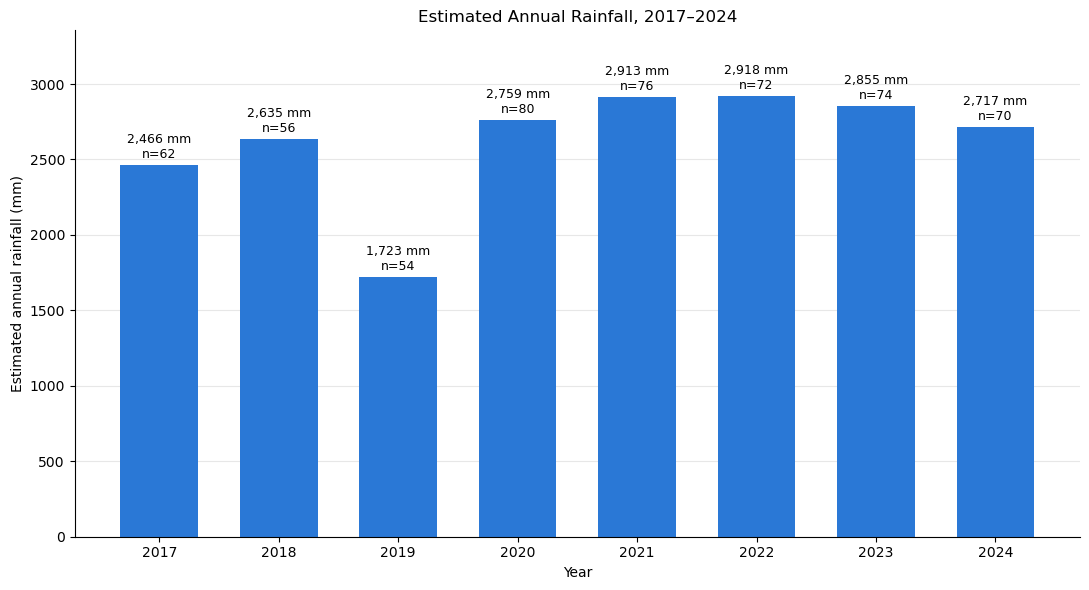

In [25]:


# Step 1: Calculate mean rainfall per observed interval for each year
# The year column was created in section 1.3
annual_spk = (
    rain.filter(F.col("year").between(2017, 2024))
        .groupBy("year")
        .agg(
            F.avg("reading_value").alias("mean_per_interval"),
            F.countDistinct("station_id").alias("n_stations")
        )
        # Within 2017–2024, 2020 and 2024 are leap years
        .withColumn(
            "days",
            F.when(F.col("year") % 4 == 0, 366).otherwise(365)
        )
        # Scale the observed mean to a full year:
        # days × 24 hours × 12 five-minute intervals per hour
        .withColumn(
            "est_annual_mm",
            F.col("mean_per_interval") * F.col("days") * 24 * 12
        )
        .orderBy("year")
)

# Step 2: Display the annual estimates
annual_spk.show(truncate=False)

# Step 3: Convert the small annual summary to pandas
annual_df = annual_spk.toPandas()

# Step 4: Plot one bar for each year
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    annual_df["year"],
    annual_df["est_annual_mm"],
    color="#2a78d6",
    width=0.65
)

# Step 5: Label each bar with its rainfall estimate and station count
for bar, rainfall, n in zip(
    bars,
    annual_df["est_annual_mm"],
    annual_df["n_stations"]
):
    ax.annotate(
        f"{rainfall:,.0f} mm\nn={n}",
        xy=(bar.get_x() + bar.get_width() / 2, rainfall),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xlabel("Year")
ax.set_ylabel("Estimated annual rainfall (mm)")
ax.set_title("Estimated Annual Rainfall, 2017–2024")
ax.set_xticks(annual_df["year"])
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- **2019 has the lowest estimated annual rainfall**, at **1,723 mm**, standing out as substantially drier than the other years in this comparison.
- **2022 has the highest estimate**, at **2,918 mm**, closely followed by **2021 at 2,913 mm**.
- Estimated rainfall rises sharply after 2019, remains relatively high during 2020–2023, and decreases to **2,717 mm in 2024**.
- The results show **year-to-year variation rather than a steady increase or decrease** over the eight-year period.
- The number of reporting stations varies from **54 to 80**. Changes in station composition and missing observations may influence these estimates, so the differences cannot be attributed entirely to weather without further coverage checks.

## 1.4 Monthly Rainfall Across the Years

Following the annual comparison, this chart examines estimated rainfall for each month from 2017 to 2024 to identify wetter months, drier periods and unusual peaks.

Unlike Section 1.3, which averages the same calendar month across years, this timeline keeps all 96 year–months separate. This shows how individual years follow or depart from the typical seasonal pattern.

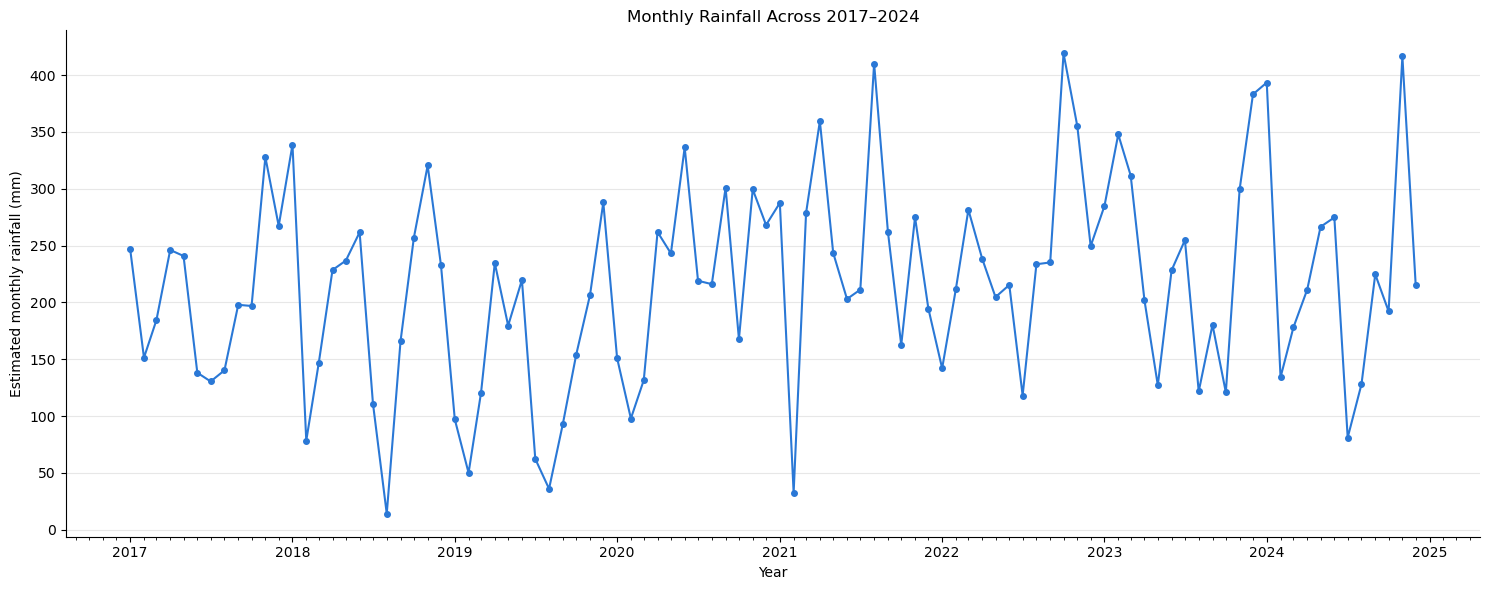

In [26]:
# Step 1: Retrieve the monthly estimates in chronological order
# Keep all 96 year-months, rather than averaging them into 12 calendar months
monthly_df = (
    monthly_spk.orderBy("year_month")
        .toPandas()
)

monthly_df["year_month"] = pd.to_datetime(monthly_df["year_month"])

# Step 2: Plot estimated rainfall for each month from 2017 to 2024
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    monthly_df["year_month"],
    monthly_df["avg_rainfall_monthly"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    color="#2a78d6"
)

# Step 3: Label the timeline by year, with smaller ticks for individual months
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())

ax.set_xlabel("Year")
ax.set_ylabel("Estimated monthly rainfall (mm)")
ax.set_title("Monthly Rainfall Across 2017–2024")

ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- Estimated monthly rainfall fluctuates substantially, ranging from **below 50 mm to over 400 mm**, showing considerable variation within and between years.
- Several relatively low-rainfall months occur in **2019**, consistent with its lower annual rainfall estimate.
- Prominent monthly peaks exceeding **400 mm** occur in **2021, 2022 and 2024**.
- Although the seasonal profile shows November as the wettest month on average, individual years differ in the timing and size of their rainfall peaks.
- The timeline shows repeated rises and falls rather than a steady upward or downward pattern. Annual averages therefore conceal substantial month-to-month variation.
- These are estimates based on available readings. Very low monthly values should be interpreted cautiously because missing observations or changes in station coverage may also affect them.

## 1.5 Time-of-Day Patterns: When Does Rainfall Occur?

This section examines how rainfall varies by hour of day and calendar month across 2017–2024.

The heatmap shows the mean rainfall per observed five-minute interval for each month–hour combination, combining readings across stations and years. Darker colours indicate larger average rainfall amounts, helping identify whether the daily rainfall pattern changes through the year.

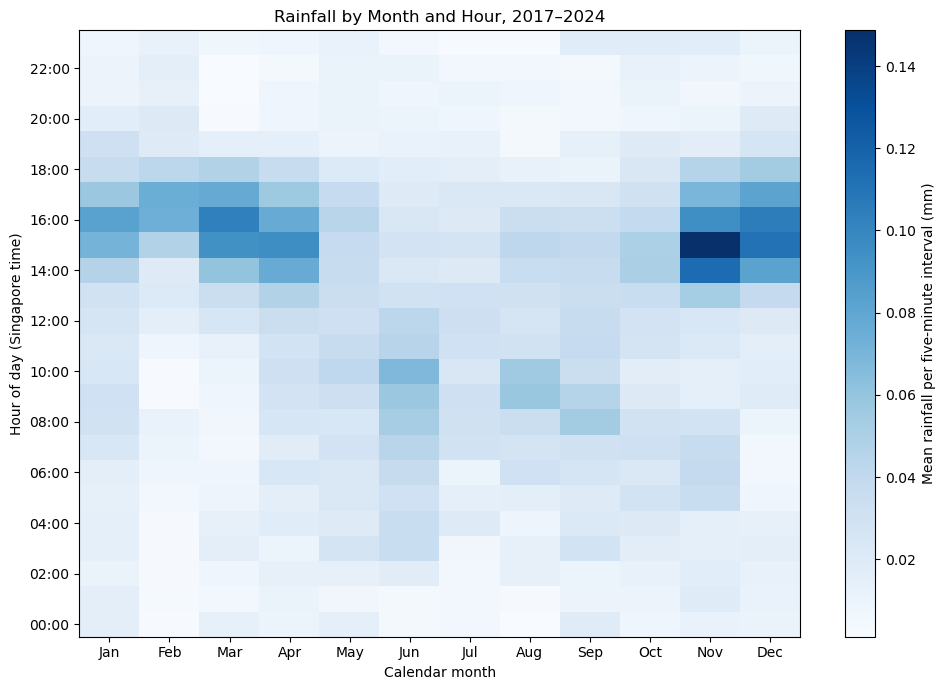

In [27]:
# Step 1: Interpret observation hours in Singapore time
# Assumes timestamp has already been converted to a timestamp type
spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

# Step 2: Group readings by calendar month and hour of day
hour_month_spk = (
    rain.filter(F.year("timestamp").between(2017, 2024))
        .withColumn("month", F.month("timestamp"))
        .withColumn("hour", F.hour("timestamp"))
        .groupBy("month", "hour")
        .agg(
            F.avg("reading_value").alias("mean_interval_mm"),
            F.count("*").alias("n_readings")
        )
        .orderBy("month", "hour")
)

# Step 3: Convert the small summary to pandas
hour_month_df = hour_month_spk.toPandas()

# Step 4: Arrange the results into a grid
# Rows = hours; columns = calendar months
# Missing combinations remain blank rather than becoming zero
grid = (
    hour_month_df.pivot(
        index="hour",
        columns="month",
        values="mean_interval_mm"
    )
    .reindex(index=range(24), columns=range(1, 13))
)

# Step 5: Plot the heatmap
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    grid.values,
    aspect="auto",
    origin="lower",
    cmap="Blues"
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

ax.set_xticks(range(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(range(0, 24, 2))
ax.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])

ax.set_xlabel("Calendar month")
ax.set_ylabel("Hour of day (Singapore time)")
ax.set_title("Rainfall by Month and Hour, 2017–2024")
ax.grid(False)

fig.colorbar(
    im,
    ax=ax,
    label="Mean rainfall per five-minute interval (mm)"
)

plt.tight_layout()
plt.show()

- **Afternoon rainfall is prominent**, particularly around **14:00–17:00** in January–April and November–December.
- **November shows the strongest afternoon peak**, especially around **15:00**, where the mean rainfall per five-minute interval is highest.
- **Morning rainfall is relatively more prominent in June, August and September**, particularly around **08:00–11:00**, showing that the daily rainfall pattern varies by month.
- Overnight hours generally have lower mean rainfall than the main daytime peaks.
- These patterns suggest that **month and hour together** may be useful predictors for Task 2.
- The colours represent **average five-minute rainfall amounts**, not the probability of rain. Higher averages may reflect more frequent rain, larger amounts when it rains, or both.

## 1.6 Rainfall Frequency and Intensity: More Frequent or Heavier Rain?

Rainfall totals alone do not show whether rain occurs more often or falls in larger amounts.

We therefore compare two measures for each month:
- **Frequency:** The percentage of five-minute readings with rainfall greater than zero.
- **Intensity:** The average rainfall amount among those positive readings.

Together, these measures help explain differences in rainfall between months.

+-----+----------+---------------+--------------------+------------------+
|month|n_readings|n_wet_intervals|mean_wet_interval_mm|wet_interval_pct  |
+-----+----------+---------------+--------------------+------------------+
|1    |3903365   |171005         |0.6234151337096163  |4.380963604479724 |
|2    |3679904   |77716          |0.8637931706471005  |2.111902919206588 |
|3    |4057990   |102734         |0.9508237945568221  |2.5316474412209   |
|4    |3784146   |106909         |1.023996099299362   |2.8251816922497177|
|5    |4067817   |101133         |0.9727182920510683  |2.4861737880538874|
|6    |4029868   |126141         |0.8727506840758588  |3.1301521538670745|
|7    |4220080   |81872          |0.8934188975475662  |1.940058008378988 |
|8    |3739148   |89466          |0.8935015965841797  |2.3926841087862796|
|9    |4259809   |118822         |0.8892659172544605  |2.789373889768297 |
|10   |4380392   |120363         |0.8596047800404739  |2.7477677796872975|
|11   |4110296   |167496 

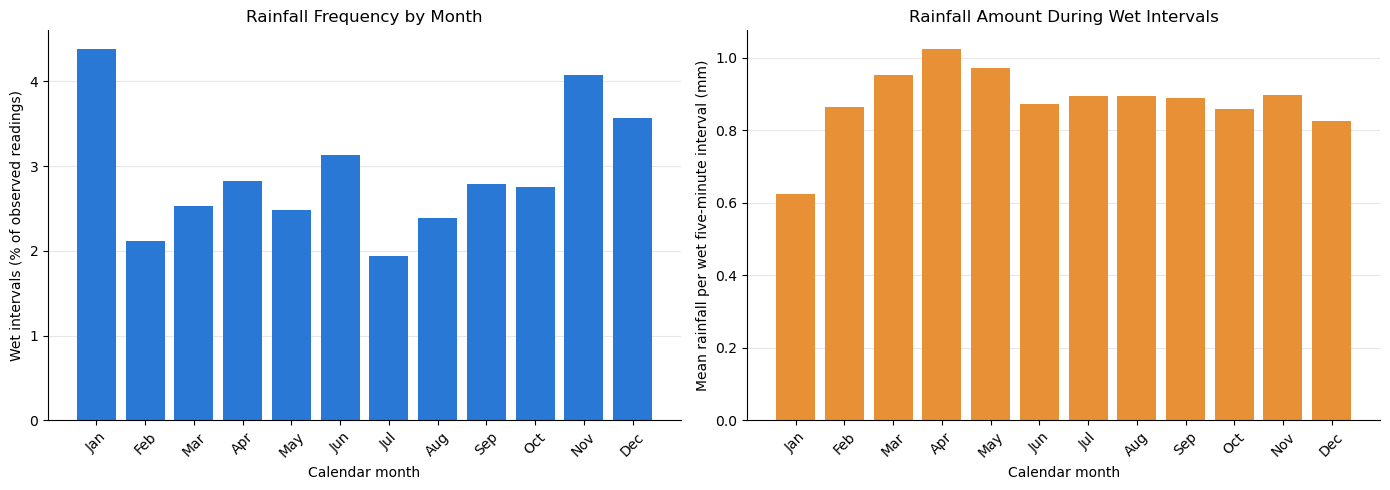

In [28]:

# Step 1: Summarise readings by calendar month across 2017–2024
# For example, all January readings are grouped together
rainfall_frequency_intensity = (
    rain.filter(F.year("timestamp").between(2017, 2024))
        .withColumn("month", F.month("timestamp"))
        .groupBy("month")
        .agg(
            # Count observed rainfall values, excluding nulls
            F.count("reading_value").alias("n_readings"),

            # Count intervals where rainfall is greater than zero
            F.count(
                F.when(F.col("reading_value") > 0, 1)
            ).alias("n_wet_intervals"),

            # Average rainfall only across positive readings
            F.avg(
                F.when(
                    F.col("reading_value") > 0,
                    F.col("reading_value")
                )
            ).alias("mean_wet_interval_mm")
        )
        # Step 2: Express wet intervals as a percentage of observed readings
        .withColumn(
            "wet_interval_pct",
            F.when(
                F.col("n_readings") > 0,
                100.0 * F.col("n_wet_intervals") / F.col("n_readings")
            )
        )
        .orderBy("month")
)

# Step 3: Display the calculated results
rainfall_frequency_intensity.show(12, truncate=False)

# Step 4: Convert the small summary to pandas
# Keep missing months as missing values rather than filling them with zero
fi_df = (
    rainfall_frequency_intensity.toPandas()
        .set_index("month")
        .reindex(range(1, 13))
)

# Step 5: Plot frequency and intensity separately because their units differ
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: How often is rain recorded?
axes[0].bar(
    fi_df.index,
    fi_df["wet_interval_pct"],
    color="#2a78d6"
)
axes[0].set_title("Rainfall Frequency by Month")
axes[0].set_ylabel("Wet intervals (% of observed readings)")

# Right chart: How much rain falls during a wet interval?
axes[1].bar(
    fi_df.index,
    fi_df["mean_wet_interval_mm"],
    color="#e89036"
)
axes[1].set_title("Rainfall Amount During Wet Intervals")
axes[1].set_ylabel("Mean rainfall per wet five-minute interval (mm)")

for ax in axes:
    ax.set_xlabel("Calendar month")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels, rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- **January has the highest rainfall frequency**, with approximately **4.4%** of observed intervals recording rain. However, it has the **lowest mean amount per wet interval**, at around **0.62 mm**. Rain is recorded relatively often, but in smaller amounts.
- **April has the highest mean rainfall per wet interval**, at approximately **1.02 mm**, although its wet-interval frequency is lower than January’s. This indicates larger amounts when rain occurs.
- **November combines relatively high frequency and intensity**, with around **4.1%** wet intervals and **0.9 mm** per wet interval. This is consistent with its high estimated monthly rainfall.
- **July has the lowest wet-interval frequency**, at approximately **1.8%**, despite averaging around **0.9 mm** when rain is recorded. Its relatively low monthly rainfall is therefore associated with fewer wet intervals.
- These results show that **frequent rainfall does not necessarily mean heavier rainfall**. Both frequency and the amount recorded during wet intervals help explain monthly differences.
- The percentages describe observed station-level five-minute readings, not the percentage of rainy days or the number of separate storms.